# 1. Duality

To illustrate the duality between Voronoi diagrams and Delaunay triangulations, we generate 10 random points and plot the Voronoi diagram and the Delaunay triangulation in the same figure.

In [15]:
import numpy as np
from scipy.spatial import Voronoi, voronoi_plot_2d
from scipy.spatial import Delaunay, delaunay_plot_2d
from matplotlib import pyplot as plt

In [16]:
points = np.random.rand(10, 2)
points

array([[0.08045616, 0.54896579],
       [0.51040809, 0.72308511],
       [0.88401085, 0.67644828],
       [0.60852495, 0.36329837],
       [0.26567785, 0.91470375],
       [0.22993352, 0.39451029],
       [0.0249028 , 0.48277501],
       [0.37975105, 0.59385192],
       [0.01155054, 0.51977919],
       [0.74809937, 0.56587863]])

The points are the sites in the Voronoi diagram.

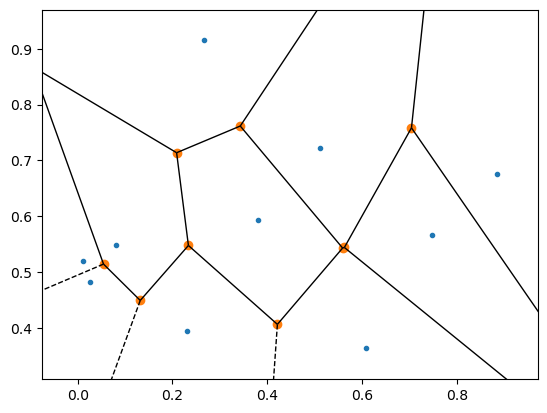

In [17]:
vor = Voronoi(points)
voronoi_plot_2d(vor)
plt.show()

The point set is the vertex set of the Delaunay triangulation.

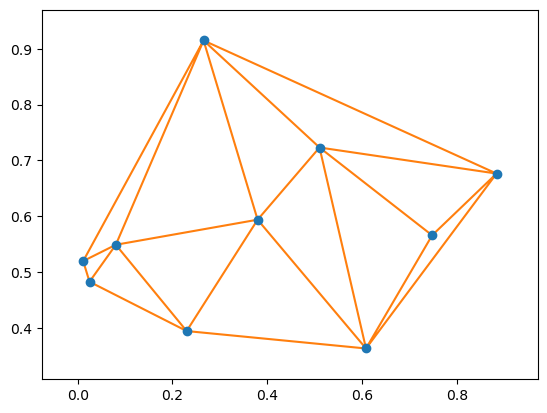

In [18]:
tri = Delaunay(points)
delaunay_plot_2d(tri)
plt.show()

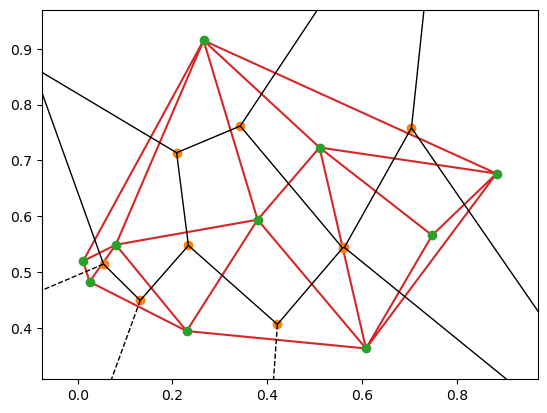

In [19]:
fig, axs = plt.subplots()
voronoi_plot_2d(vor, ax=axs)
delaunay_plot_2d(tri, ax=axs)
plt.show()

Observe the duality as follows: sites in adjacent Voronoi cells are connected by an edge.  Those connecting edges are the edges of the triangles in the Delaunay triangulation.

# 2. The Delaunay Triangulation in CGAL

In [20]:
from CGAL.CGAL_Kernel import Point_2
from CGAL.CGAL_Triangulation_2 import Delaunay_triangulation_2

The set of 10 random points in `points` is used.

In [21]:
P = [Point_2(x, y) for (x, y) in points]
for point in P:
    print(point)

0.0804562 0.548966
0.510408 0.723085
0.884011 0.676448
0.608525 0.363298
0.265678 0.914704
0.229934 0.39451
0.0249028 0.482775
0.379751 0.593852
0.0115505 0.519779
0.748099 0.565879


In [22]:
T = Delaunay_triangulation_2()

In [23]:
for point in P:
    T.insert(point)

In [24]:
T.number_of_vertices()

10

In [25]:
for v in T.finite_vertices():
    print(v.point())

0.0804562 0.548966
0.510408 0.723085
0.884011 0.676448
0.608525 0.363298
0.265678 0.914704
0.229934 0.39451
0.0249028 0.482775
0.379751 0.593852
0.0115505 0.519779
0.748099 0.565879


In [26]:
T.number_of_faces()

12

In [27]:
for f in T.finite_faces():
    print(T.triangle(f))

0.379751 0.593852 0.0804562 0.548966 0.229934 0.39451
0.265678 0.914704 0.510408 0.723085 0.884011 0.676448
0.748099 0.565879 0.608525 0.363298 0.884011 0.676448
0.0804562 0.548966 0.379751 0.593852 0.265678 0.914704
0.510408 0.723085 0.379751 0.593852 0.608525 0.363298
0.0804562 0.548966 0.0249028 0.482775 0.229934 0.39451
0.0804562 0.548966 0.265678 0.914704 0.0115505 0.519779
0.608525 0.363298 0.379751 0.593852 0.229934 0.39451
0.510408 0.723085 0.265678 0.914704 0.379751 0.593852
0.0249028 0.482775 0.0804562 0.548966 0.0115505 0.519779
0.510408 0.723085 0.748099 0.565879 0.884011 0.676448
0.510408 0.723085 0.608525 0.363298 0.748099 0.565879


In [28]:
for e in T.finite_edges():
    print(T.segment(e))

0.265678 0.914704 0.884011 0.676448
0.0804562 0.548966 0.229934 0.39451
0.229934 0.39451 0.379751 0.593852
0.379751 0.593852 0.0804562 0.548966
0.608525 0.363298 0.229934 0.39451
0.884011 0.676448 0.608525 0.363298
0.510408 0.723085 0.884011 0.676448
0.265678 0.914704 0.510408 0.723085
0.884011 0.676448 0.748099 0.565879
0.748099 0.565879 0.608525 0.363298
0.0115505 0.519779 0.265678 0.914704
0.379751 0.593852 0.265678 0.914704
0.265678 0.914704 0.0804562 0.548966
0.379751 0.593852 0.608525 0.363298
0.608525 0.363298 0.510408 0.723085
0.510408 0.723085 0.379751 0.593852
0.229934 0.39451 0.0249028 0.482775
0.0804562 0.548966 0.0249028 0.482775
0.0115505 0.519779 0.0804562 0.548966
0.0249028 0.482775 0.0115505 0.519779
0.510408 0.723085 0.748099 0.565879


It is a good exercise to use `matplotlib` to plot the Delaunay triangulation computed by CGAL.

Another exercise is to verify the duality with the Voronoi diagram computed by CGAL, see an earlier lecture.